# Sensitivities

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib notebook

In [120]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.ticker import MultipleLocator
from scipy import stats
from astropy import units as u
from astropy import constants as c
from astropy.coordinates import SkyCoord
from pathlib import Path
# PlatoSim libraries
import platosim.plot      as pt
import platosim.utilities as ut
from platosim.matplotlibrc import setup_notebook
setup_notebook()
# Adjust notebook
from IPython.display import display, HTML
display(HTML("<style>.container {width:100% !important; }</style>"))
# Random generator
seed = 123456789
rng = ut.rng(seed)

In [4]:
# Paths to where data is stored
hdir = ut.getHomeDir('inputfiles/data_picsim')
path = ut.getWorkDir('moonwalk')
idir = path / 'input'
fdir = Path('/lhome/nicholas/Nextcloud/latex/papers/2027_Moonwalk/figures')

---
## Define Solar System parameters
---

In [59]:
# Parameters of Sun, planets, and all moons with (R > 100 km)
R_sun     = 695_700
Jupiter   = {'R': 71_492, 'M': 1.898e27, 'rho': 1.326}
Saturn    = {'R': 58_232, 'M': 5.683e26, 'rho': 0.687}
Uranus    = {'R': 25_362, 'M': 8.681e25, 'rho': 1.270}
Neptune   = {'R': 24_622, 'M': 1.024e26, 'rho': 1.638}
Earth     = {'R':  6_371, 'M': 5.972e24, 'rho': 5.515}
Mars      = {'R':  3_390, 'M': 6.417e23, 'rho': 3.934}
# Earth's moon
Moon      = {'a':   384_399, 'R': 1737, 'M': 7.348e22, 'rho': 3.34}
# Jupiter's moons
Ganymede  = {'a': 1_070_400, 'R': 2631, 'M': 1.482e23, 'rho': 1.94}
Callisto  = {'a': 1_882_700, 'R': 2410, 'M': 1.076e23, 'rho': 1.83}
Io        = {'a':   421_800, 'R': 1822, 'M': 8.932e22, 'rho': 3.53}
Europa    = {'a':   671_100, 'R': 1561, 'M': 4.780e22, 'rho': 3.01}
# Saturn's moons
Titan     = {'a': 1_221_950, 'R': 2575, 'M': 1.345e23, 'rho': 1.88}
Rhea      = {'a':   527_108, 'R':  765, 'M': 2.307e21, 'rho': 1.23}
Dione     = {'a':   377_396, 'R':  560, 'M': 1.096e21, 'rho': 1.48}
Tethys    = {'a':   294_619, 'R':  530, 'M': 6.175e20, 'rho': 0.98}
Enceladus = {'a':   237_948, 'R':  250, 'M': 1.080e20, 'rho': 1.61}
Mimas     = {'a':   185_539, 'R':  196, 'M': 3.751e19, 'rho': 1.15}
# Uranus' moons
Titania   = {'a':   129_858, 'R':  789, 'M': 3.508e21, 'rho': 1.70}
Oberon    = {'a':   583_449, 'R':  760, 'M': 3.209e21, 'rho': 1.74}
Umbriel   = {'a':   265_982, 'R':  585, 'M': 1.270e21, 'rho': 1.49}
Ariel     = {'a':   190_930, 'R':  580, 'M': 1.250e21, 'rho': 1.55} 
Miranda   = {'a':   129_858, 'R':  235, 'M': 6.160e19, 'rho': 1.12}
# Neptune's moons
Triton    = {'a':   354_760, 'R': 1353, 'M': 2.140e22, 'rho': 2.06}
Proteus   = {'a':   117_647, 'R':  210, 'M': 4.400e19, 'rho': 1.30}

---
## Transit sensitivities
---

In [216]:
def transit_depth(R_moon, R_star=R_sun):
    """Calculate transit depths [ppm]
    """
    return (R_moon / R_star)**2 * 1e6

def noise(mag, ncam, rms=0.04, tdur=3600, passband='P', camtype='normal'):
    """Three rocket noise model of PLATO
    """
    noise_jitter     = ut.getJitterNoiseLimitNSR(rms, tdur=tdur, camType=camtype)
    noise_photon     = ut.getPhotonNoiseLimitNSR(mag, passband, ncam=ncam)
    noise_background = ut.getBackgroundNoiseLimitNSR(mag, passband, ncam=ncam)
    return np.sqrt(noise_jitter**2 + noise_photon**2 + noise_background**2)

def snr_transit(N, depth, noise):
    """Detection efficiency (Cabrera+2026, Eq.9)
    """
    return np.sqrt(N) * depth / noise

def parameter_ratio(moon, planet):
    """Return scaled moon parameters
    """
    Jup = np.array([Ganymede[moon], Callisto[moon], Io[moon], Europa[moon]]) / Jupiter[planet]
    Sat = np.array([Titan[moon], Rhea[moon], Dione[moon], Tethys[moon], Enceladus[moon], Mimas[moon]]) / Saturn[planet]
    Ura = np.array([Titania[moon], Oberon[moon], Umbriel[moon], Ariel[moon], Miranda[moon]]) / Uranus[planet]
    Nep = np.array([Triton[moon], Proteus[moon]]) / Neptune[planet]
    Ear = np.array([Moon[moon]]) / Earth[planet]
    moons = np.concatenate([Jup, Sat, Ura, Nep])
    return moons, Jup, Sat, Ura, Nep

def make_kde(x, y, n_grid=1000j, xe_max=0.1, xe_min=0.1, ye_min=0.1, ye_max=0.1):
    """Make KDE map from (x,y) dataset.
    """
    xmin, xmax = x.min()-x.min()*xe_min, x.max()+x.min()*xe_max
    ymin, ymax = y.min()-y.min()*ye_min, y.max()+y.min()*ye_max
    X, Y = np.mgrid[xmin:xmax:n_grid, ymin:ymax:n_grid]
    positions = np.vstack([X.ravel(), Y.ravel()])
    values = np.vstack([x, y])
    kernel = stats.gaussian_kde(values)
    Z = np.reshape(kernel.evaluate(positions), X.shape)
    return X, Y, Z

def draw_from_kde(x, y, Z, N=1000):
    """Draw N points from 2D KDE map.
    """
    linear_idx = np.random.choice(Z.size, N, p=Z.ravel()/float(Z.sum()))
    xx, yy = np.unravel_index(linear_idx, Z.shape)
    return xx/xx.max()*x.max(), yy/yy.max()*y.max()

### Solar system architectures

In [207]:
# Scaled semi-major axes
a_moons, a_Jup, a_Sat, a_Ura, a_Nep = parameter_ratio('a', 'R')
# Mass ratios
M_moons, M_Jup, M_Sat, M_Ura, M_Nep = parameter_ratio('M', 'M')
# Mass ratios
R_moons, R_Jup, R_Sat, R_Ura, R_Nep = parameter_ratio('R', 'R')
# Density ratios
rho_moons, rho_Jup, rho_Sat, rho_Ura, rho_Nep = parameter_ratio('rho', 'rho')

<IPython.core.display.Javascript object>


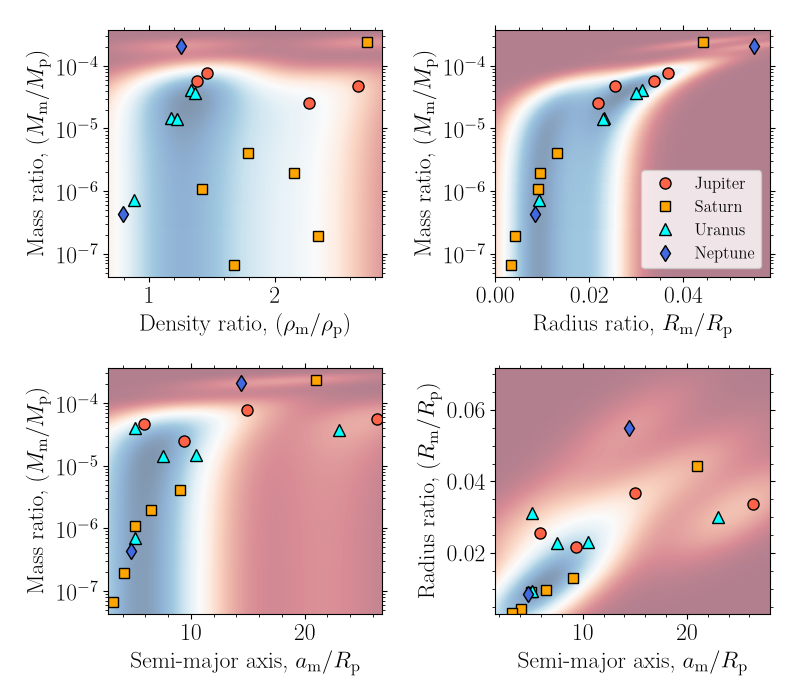

In [248]:
# PLOT FOR PAPER
fig, ax = plt.subplots(2, 2, figsize=(8,7))
# Parameters
aa, ms, lw = 1, 8, 1.5
mk = ['o', 's', '^', 'd', 'D']
cc = ['tomato', 'orange', 'cyan', 'royalblue', 'lime']
mx = ms-1
# Plot mass ratios vs. density ratios
X, Y, Z = make_kde(rho_moons, M_moons, xe_min=0.15, xe_max=0.15, ye_max=2e3)
ax[0,0].pcolormesh(X, Y, Z, cmap='RdBu', alpha=0.5)
ax[0,0].plot(rho_Jup, M_Jup, mk[0], ms=ms, mec='k', alpha=aa, c=cc[0])
ax[0,0].plot(rho_Sat, M_Sat, mk[1], ms=mx, mec='k', alpha=aa, c=cc[1])
ax[0,0].plot(rho_Ura, M_Ura, mk[2], ms=ms, mec='k', alpha=aa, c=cc[2])
ax[0,0].plot(rho_Nep, M_Nep, mk[3], ms=ms, mec='k', alpha=aa, c=cc[3])
ax[0,0].set_xlabel(r'Density ratio, $(\rho_{\rm m}/\rho_{\rm p})$')
ax[0,0].set_ylabel(r'Mass ratio, $(M_{\rm m}/M_{\rm p})$')
ax[0,0].set_yscale('log')
# Plot of a_moon vs. depth_moon
X, Y, Z = make_kde(R_moons, M_moons, xe_min=1, xe_max=1, ye_max=2e3)
ax[0,1].pcolormesh(X, Y, Z, cmap='RdBu', alpha=0.5)
ax[0,1].plot(R_Jup, M_Jup, mk[0], ms=ms, mec='k', alpha=aa, c=cc[0], label='Jupiter')
ax[0,1].plot(R_Sat, M_Sat, mk[1], ms=mx, mec='k', alpha=aa, c=cc[1], label='Saturn')
ax[0,1].plot(R_Ura, M_Ura, mk[2], ms=ms, mec='k', alpha=aa, c=cc[2], label='Uranus')
ax[0,1].plot(R_Nep, M_Nep, mk[3], ms=ms, mec='k', alpha=aa, c=cc[3], label='Neptune')
ax[0,1].set_xlabel(r'Radius ratio, $R_{\rm m}/R_{\rm p}$')
ax[0,1].set_ylabel(r'Mass ratio, $(M_{\rm m}/M_{\rm p})$')
ax[0,1].set_yscale('log')
ax[0,1].legend(fontsize=12, loc='lower right')
# Plot of semi-major axis vs. mass ratio
X, Y, Z = make_kde(a_moons, M_moons, xe_min=0.15, xe_max=0.15, ye_max=2e3)
ax[1,0].pcolormesh(X, Y, Z, cmap='RdBu', alpha=0.5)
ax[1,0].plot(a_Jup, M_Jup, mk[0], ms=ms, mec='k', alpha=aa, c=cc[0])
ax[1,0].plot(a_Sat, M_Sat, mk[1], ms=mx, mec='k', alpha=aa, c=cc[1])
ax[1,0].plot(a_Ura, M_Ura, mk[2], ms=ms, mec='k', alpha=aa, c=cc[2])
ax[1,0].plot(a_Nep, M_Nep, mk[3], ms=ms, mec='k', alpha=aa, c=cc[3])
ax[1,0].set_xlabel(r'Semi-major axis, $a_{\rm m}/R_{\rm p}$')
ax[1,0].set_ylabel(r'Mass ratio, $(M_{\rm m}/M_{\rm p})$')
ax[1,0].set_yscale('log')
# Plot semi-major axis vs. radius ratio
X, Y, Z = make_kde(a_moons, R_moons, xe_min=0.5, xe_max=0.5, ye_max=5)
ax[1,1].pcolormesh(X, Y, Z, cmap='RdBu', alpha=0.5)
ax[1,1].plot(a_Jup, R_Jup, mk[0], ms=ms, mec='k', alpha=aa, c=cc[0])
ax[1,1].plot(a_Sat, R_Sat, mk[1], ms=mx, mec='k', alpha=aa, c=cc[1])
ax[1,1].plot(a_Ura, R_Ura, mk[2], ms=ms, mec='k', alpha=aa, c=cc[2])
ax[1,1].plot(a_Nep, R_Nep, mk[3], ms=ms, mec='k', alpha=aa, c=cc[3])
ax[1,1].set_xlabel(r'Semi-major axis, $a_{\rm m}/R_{\rm p}$')
ax[1,1].set_ylabel(r'Radius ratio, $(R_{\rm m}/R_{\rm p})$')
# ax[1,1].set_yscale('log')
# Settings
plt.tight_layout();
# fig.savefig(fdir / 'prediction_solar.png', bbox_inches='tight', dpi=200)

In [227]:
# # PLOT TESTING DISTRIBUTIONS
# fig, ax = plt.subplots(1, 2, figsize=(8, 4))
# # Parameters
# aa, ms, lw = 1, 8, 1.5
# mk = ['o', 's', '^', 'd', 'D']
# cc = ['tomato', 'orange', 'cyan', 'royalblue', 'lime']
# mx = ms-1
# # Plot mass ratios vs. density ratios
# X, Y, Z = make_kde(rho_moons, M_moons, xmax_extra=1e3)
# ax[0].pcolormesh(X, Y, Z, cmap='RdBu', alpha=0.5)
# ax[0].axhline(y=1e-4, c='k', ls=':',  lw=lw)
# ax[0].axhline(y=1e-5, c='k', ls='--', lw=lw)
# ax[0].plot(rho_Jup, M_Jup, mk[0], ms=ms, mec='k', alpha=aa, c=cc[0])
# ax[0].plot(rho_Sat, M_Sat, mk[1], ms=mx, mec='k', alpha=aa, c=cc[1])
# ax[0].plot(rho_Ura, M_Ura, mk[2], ms=ms, mec='k', alpha=aa, c=cc[2])
# ax[0].plot(rho_Nep, M_Nep, mk[3], ms=ms, mec='k', alpha=aa, c=cc[3])
# ax[0].set_xlabel(r'Density ratio, $(\rho_{\rm m}/\rho_{\rm p})$')
# ax[0].set_ylabel(r'Mass ratio, $(M_{\rm m}/M_{\rm p})$')
# ax[0].set_yscale('log')
# # Plot of a_moon vs. depth_moon
# ax[1].axhline(y=10, c='k', ls='--', lw=lw)
# ax[1].plot(a_Jup, transit_depth(R_Jup), mk[0], ms=ms, mec='k', alpha=aa, c=cc[0], label='Jupiter')
# ax[1].plot(a_Sat, transit_depth(R_Sat), mk[1], ms=mx, mec='k', alpha=aa, c=cc[1], label='Saturn')
# ax[1].plot(a_Ura, transit_depth(R_Ura), mk[2], ms=ms, mec='k', alpha=aa, c=cc[2], label='Uranus')
# ax[1].plot(a_Nep, transit_depth(R_Nep), mk[3], ms=ms, mec='k', alpha=aa, c=cc[3], label='Neptune')
# ax[1].set_xlabel(r'Semi-major axis, $a_{\rm m}/R_{\rm p}$')
# ax[1].set_ylabel(r'Transit depth, $\delta_{\rm m}$ [ppm]')
# ax[1].set_yscale('log')
# ax[1].legend(fontsize=12, bbox_to_anchor=(0.5, -0.1, 0.5, 0.5))
# # Settings
# plt.tight_layout();

<IPython.core.display.Javascript object>


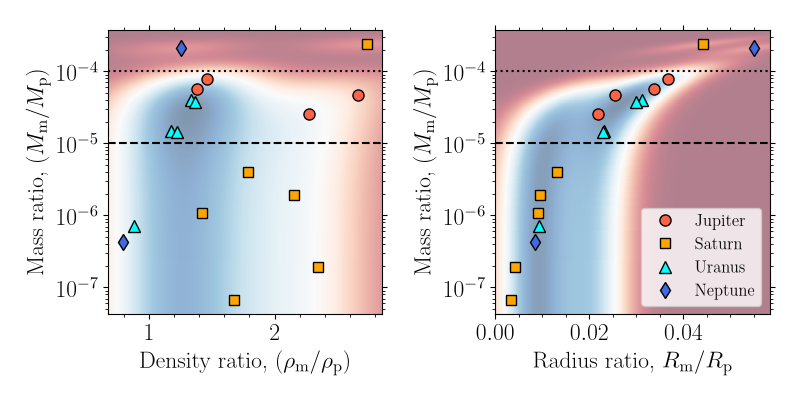

In [226]:
# PLOT FOR PAPER
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
# Parameters
aa, ms, lw = 1, 8, 1.5
mk = ['o', 's', '^', 'd', 'D']
cc = ['tomato', 'orange', 'cyan', 'royalblue', 'lime']
mx = ms-1
# Plot mass ratios vs. density ratios
X, Y, Z = make_kde(rho_moons, M_moons, xe_min=0.15, xe_max=0.15, ye_max=2e3)
ax[0].pcolormesh(X, Y, Z, cmap='RdBu', alpha=0.5)
ax[0].axhline(y=1e-4, c='k', ls=':',  lw=lw)
ax[0].axhline(y=1e-5, c='k', ls='--', lw=lw)
ax[0].plot(rho_Jup, M_Jup, mk[0], ms=ms, mec='k', alpha=aa, c=cc[0])
ax[0].plot(rho_Sat, M_Sat, mk[1], ms=mx, mec='k', alpha=aa, c=cc[1])
ax[0].plot(rho_Ura, M_Ura, mk[2], ms=ms, mec='k', alpha=aa, c=cc[2])
ax[0].plot(rho_Nep, M_Nep, mk[3], ms=ms, mec='k', alpha=aa, c=cc[3])
ax[0].set_xlabel(r'Density ratio, $(\rho_{\rm m}/\rho_{\rm p})$')
ax[0].set_ylabel(r'Mass ratio, $(M_{\rm m}/M_{\rm p})$')
ax[0].set_yscale('log')
# Plot of a_moon vs. depth_moon
X, Y, Z = make_kde(R_moons, M_moons, xe_min=1, xe_max=1, ye_max=2e3)
ax[1].axhline(y=1e-4, c='k', ls=':',  lw=lw)
ax[1].axhline(y=1e-5, c='k', ls='--', lw=lw)
ax[1].pcolormesh(X, Y, Z, cmap='RdBu', alpha=0.5)
ax[1].plot(R_Jup, M_Jup, mk[0], ms=ms, mec='k', alpha=aa, c=cc[0], label='Jupiter')
ax[1].plot(R_Sat, M_Sat, mk[1], ms=mx, mec='k', alpha=aa, c=cc[1], label='Saturn')
ax[1].plot(R_Ura, M_Ura, mk[2], ms=ms, mec='k', alpha=aa, c=cc[2], label='Uranus')
ax[1].plot(R_Nep, M_Nep, mk[3], ms=ms, mec='k', alpha=aa, c=cc[3], label='Neptune')
ax[1].set_xlabel(r'Radius ratio, $R_{\rm m}/R_{\rm p}$')
ax[1].set_ylabel(r'Mass ratio, $(M_{\rm m}/M_{\rm p})$')
ax[1].set_yscale('log')
ax[1].legend(fontsize=12, loc='lower right')
# Settings
plt.tight_layout();
fig.savefig(fdir / 'prediction_solar.png', bbox_inches='tight', dpi=200)

### Test drawing from density/mass ratio KDE map

<IPython.core.display.Javascript object>


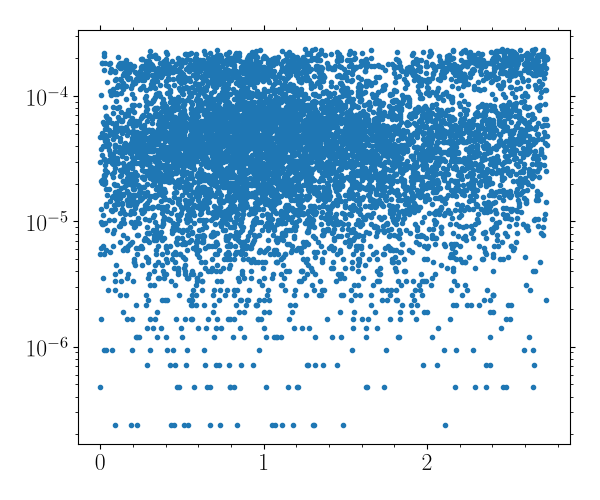

In [195]:
x, y = draw_from_kde(rho_moons, M_moons, Z, N=8000)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
ax.plot(x, y, '.')
ax.set_yscale('log')
plt.tight_layout()

<IPython.core.display.Javascript object>


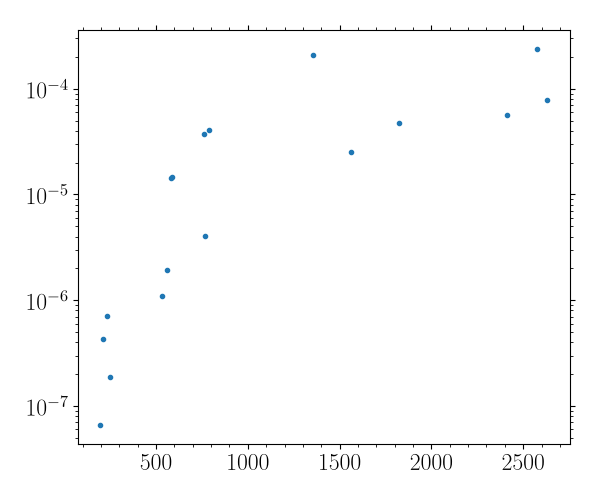

In [204]:
# rho = (x * u.g / u.cm**3).cgs
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
ax.plot(R_moons, M_moons, '.')
ax.set_yscale('log')
plt.tight_layout()

### Transit Detection Efficiency (TDE): G0V star (R=1Rsun)

<IPython.core.display.Javascript object>


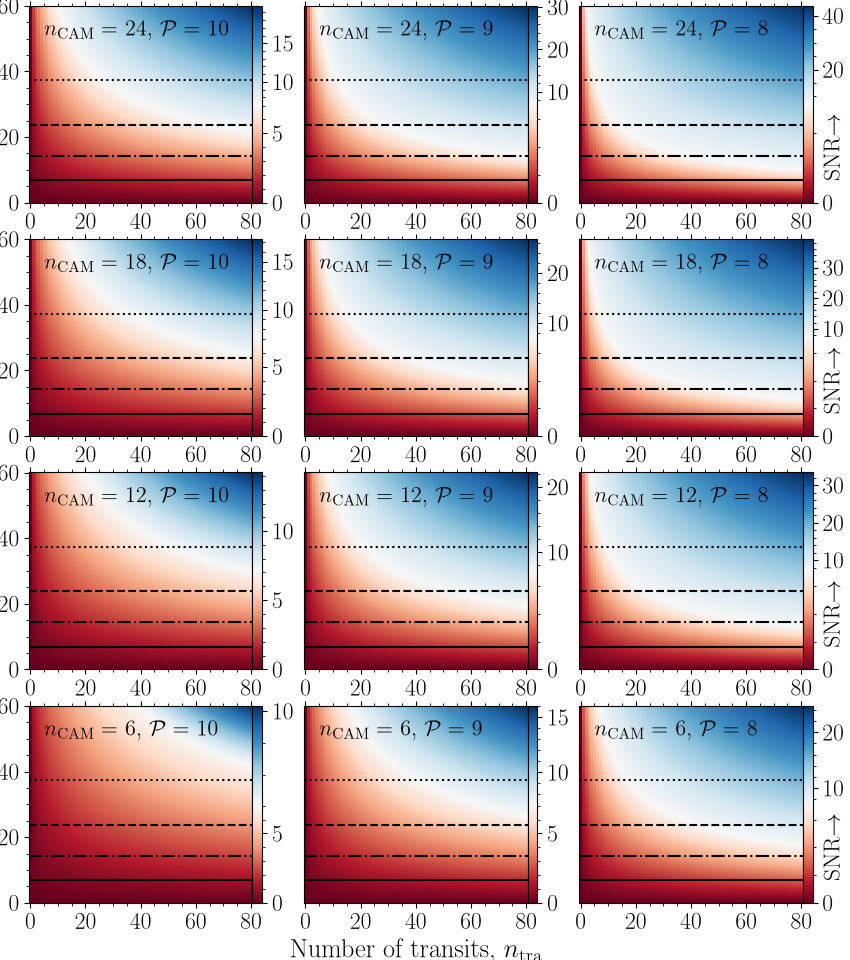

In [35]:
# Parameters
snr = 7.1
n_grid = 1000
delta_max = 60
ntran_max = 80
fs = 19
# Plotting
delta = np.linspace(0, delta_max, 1000)
ntran = np.linspace(0, ntran_max, ntran_max)
ncams = [24, 18, 12, 6]
J,I = 4,3
fig, ax = plt.subplots(J, I, figsize=(8.5, 2.4*J))
for j in range(4):
    ncam = ncams[j]
    for i in range(3):
        # Handle tick labels
        ax[j,i].xaxis.set_major_locator(MultipleLocator(20))
        ax[j,i].yaxis.set_major_locator(MultipleLocator(20))
        if i > 0:
            ax[j,i].set_yticks([])            
        # Plot each planel
        mag = 10-i
        sigma = noise(mag, ncam, tdur=3600)
        xx, yy = np.meshgrid(ntran, delta)
        zz = np.sqrt(xx) * yy / sigma
        divnorm = colors.TwoSlopeNorm(vmin=zz.min(), vcenter=snr, vmax=zz.max())
        im = ax[j, i].pcolormesh(xx, yy, zz, cmap='RdBu', norm=divnorm)
        cbar = plt.colorbar(im, pad=0)
        ax[j,i].text(5, delta_max*0.85, r'$n_{\rm CAM}=$ '+f'{ncam}, '+r'$\mathcal{P}=$'+f' {mag}', fontsize=16)
        if i == 2:
            ax[j,i].text(88, 8, r'SNR$\rightarrow$', rotation='vertical')
        # Plot hlines for Galilean moons
        R = np.array([2/3*R_Earth, R_Mars, R_Ganymede, R_Io])
        ls = [':', '--', '-.', '-']
        for r,l in zip(R,ls): 
            ax[j,i].axhline(y=transit_depth(r), c='k', lw=1.5, ls=l)
# Common settings        
ax[j,1].set_xlabel(r'Number of transits, $n_{\rm tra}$', fontsize=fs)
fig.text(-0.04, 0.5, r'Transit depth, $\delta$', va='center', rotation='vertical', fontsize=fs)
plt.tight_layout(pad=-0.1);
fig.savefig(fdir / 'prediction_TDE.png', bbox_inches='tight', dpi=200)

### Transit Detection Efficiency (TDE): K7V star (R = 0.6 Rsun)

<IPython.core.display.Javascript object>


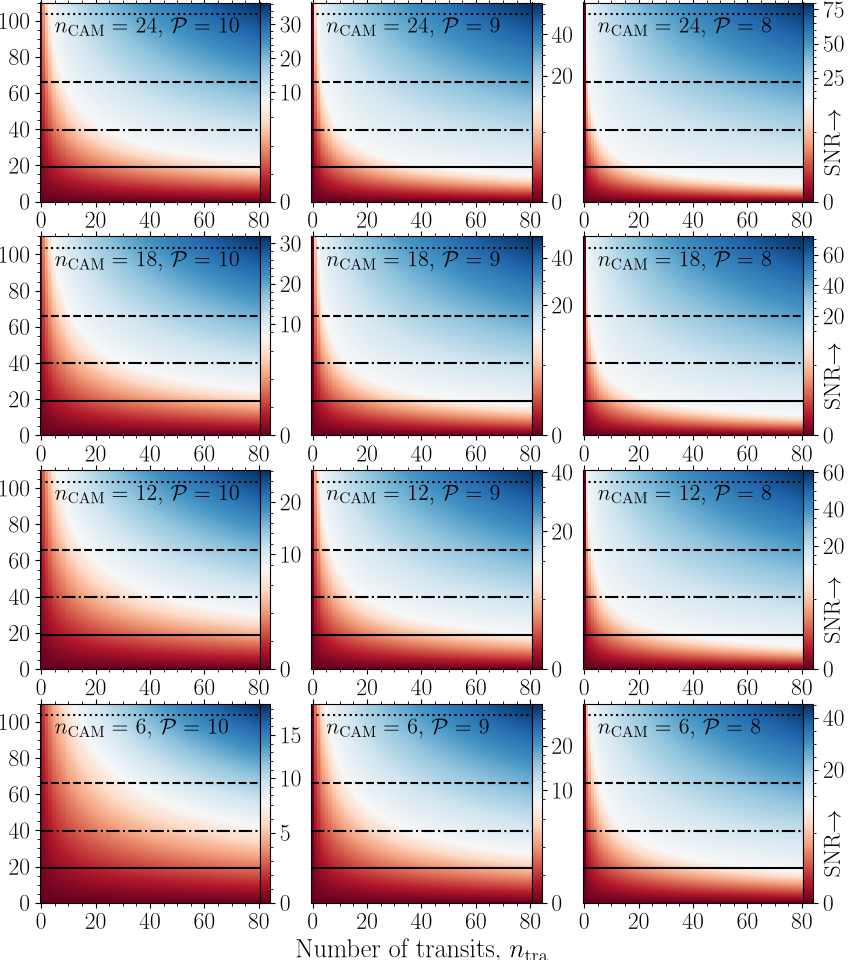

In [47]:
# Parameters
snr = 7.1
R_star = 0.6*R_sun
n_grid = 1000
delta_max = 110
ntran_max = 80
fs = 19
# Parameters for plot
delta = np.linspace(0, delta_max, 1000)
ntran = np.linspace(0, ntran_max, ntran_max)
ncams = [24, 18, 12, 6]
J,I = 4,3
# Plotting
fig, ax = plt.subplots(J, I, figsize=(8.5, 2.4*J))
for j in range(4):
    ncam = ncams[j]
    for i in range(3):
        # Handle tick labels
        ax[j,i].xaxis.set_major_locator(MultipleLocator(20))
        ax[j,i].yaxis.set_major_locator(MultipleLocator(20))
        if i > 0:
            ax[j,i].set_yticks([])            
        # Plot each planel
        mag = 10-i
        sigma = noise(mag, ncam, tdur=3600)
        xx, yy = np.meshgrid(ntran, delta)
        zz = np.sqrt(xx) * yy / sigma
        divnorm = colors.TwoSlopeNorm(vmin=zz.min(), vcenter=snr, vmax=zz.max())
        im = ax[j, i].pcolormesh(xx, yy, zz, cmap='RdBu', norm=divnorm)
        cbar = plt.colorbar(im, pad=0)
        ax[j,i].text(5, delta_max*0.85, r'$n_{\rm CAM}=$ '+f'{ncam}, '+r'$\mathcal{P}=$'+f' {mag}', fontsize=16)
        if i == 2:
            ax[j,i].text(88, delta_max*0.15, r'SNR$\rightarrow$', rotation='vertical')
        # Plot hlines for Galilean moons
        R = np.array([2/3*R_Earth, R_Mars, R_Ganymede, R_Io])
        ls = [':', '--', '-.', '-']
        for r,l in zip(R,ls): 
            ax[j,i].axhline(y=transit_depth(r, R_star=R_star), c='k', lw=1.5, ls=l)
# Common settings        
ax[j,1].set_xlabel(r'Number of transits, $n_{\rm tra}$', fontsize=fs)
fig.text(-0.04, 0.5, r'Transit depth, $\delta$', va='center', rotation='vertical', fontsize=fs)
plt.tight_layout(pad=-0.1);
# fig.savefig(fdir / 'prediction_TDE.png', bbox_inches='tight', dpi=200)

### Transit Detection Efficiency (TDE): F5V star (R = 1.5 Rsun)

<IPython.core.display.Javascript object>


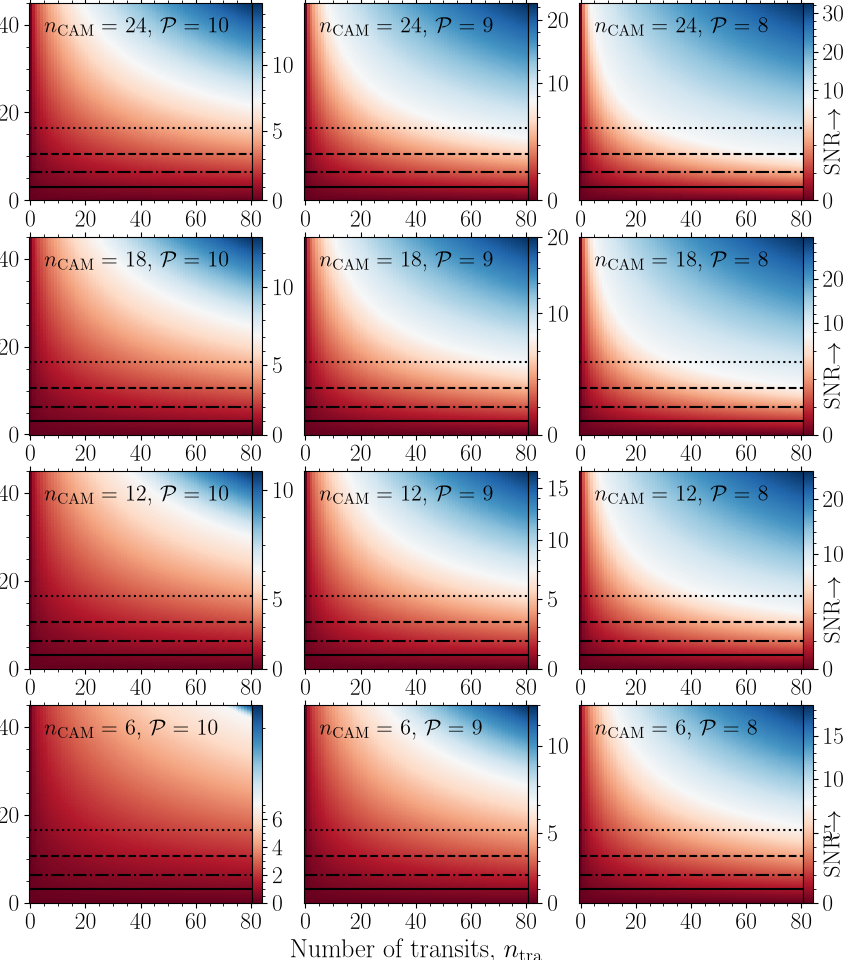

In [53]:
# Parameters
snr = 7.1
R_star = 1.5*R_sun
n_grid = 1000
delta_max = 45
ntran_max = 80
fs = 19
# Parameters for plot
delta = np.linspace(0, delta_max, 1000)
ntran = np.linspace(0, ntran_max, ntran_max)
ncams = [24, 18, 12, 6]
J,I = 4,3
# Plotting
fig, ax = plt.subplots(J, I, figsize=(8.5, 2.4*J))
for j in range(4):
    ncam = ncams[j]
    for i in range(3):
        # Handle tick labels
        ax[j,i].xaxis.set_major_locator(MultipleLocator(20))
        ax[j,i].yaxis.set_major_locator(MultipleLocator(20))
        if i > 0:
            ax[j,i].set_yticks([])            
        # Plot each planel
        mag = 10-i
        sigma = noise(mag, ncam, tdur=3600)
        xx, yy = np.meshgrid(ntran, delta)
        zz = np.sqrt(xx) * yy / sigma
        divnorm = colors.TwoSlopeNorm(vmin=zz.min(), vcenter=snr, vmax=zz.max())
        im = ax[j, i].pcolormesh(xx, yy, zz, cmap='RdBu', norm=divnorm)
        cbar = plt.colorbar(im, pad=0)
        ax[j,i].text(5, delta_max*0.85, r'$n_{\rm CAM}=$ '+f'{ncam}, '+r'$\mathcal{P}=$'+f' {mag}', fontsize=16)
        if i == 2:
            ax[j,i].text(88, delta_max*0.15, r'SNR$\rightarrow$', rotation='vertical')
        # Plot hlines for Galilean moons
        R = np.array([2/3*R_Earth, R_Mars, R_Ganymede, R_Io])
        ls = [':', '--', '-.', '-']
        for r,l in zip(R,ls): 
            ax[j,i].axhline(y=transit_depth(r, R_star=R_star), c='k', lw=1.5, ls=l)
# Common settings        
ax[j,1].set_xlabel(r'Number of transits, $n_{\rm tra}$', fontsize=fs)
fig.text(-0.04, 0.5, r'Transit depth, $\delta$', va='center', rotation='vertical', fontsize=fs)
plt.tight_layout(pad=-0.1);
# fig.savefig(fdir / 'prediction_TDE.png', bbox_inches='tight', dpi=200)